# Filtro de Bloom, filtro de cuco, *count-min* e *top-k*

Este notebook implementa por extenso as quatro estruturas da nota sobre pertinência e frequência e compara cada uma com a resposta exata: o filtro de Bloom e o filtro de cuco contra um `set`, o *count-min* e o *Space-Saving* contra um dicionário de contadores.

Os dados são sintéticos: uma lista de números de telefone e um registro de chamadas em que poucos números originam muitas chamadas (distribuição de Zipf). A escala é pequena para caber em qualquer máquina; a extrapolação para bilhões de números está nas notas.

In [1]:
import hashlib
import math
import random
import sys

import numpy as np
import matplotlib.pyplot as plt

random.seed(42)

## Dados: números de telefone

Cada número segue o formato `+55 DDD 9XXXXXXXX`. A lista `lista_bloqueio` faz o papel da lista de bloqueio de telemarketing; a lista `outros` tem números que garantidamente não estão nela e serve para medir os falsos positivos.

In [2]:
ddds = [11, 12, 13, 19, 21, 27, 31, 41, 47, 48, 51, 61, 62, 71, 81, 85, 91, 92]

def numero_aleatorio():
    ddd = random.choice(ddds)
    assinante = random.randint(0, 99_999_999)
    return f"+55{ddd}9{assinante:08d}"

todos = set()
while len(todos) < 200_000:
    todos.add(numero_aleatorio())
todos = sorted(todos)
random.shuffle(todos)

lista_bloqueio = todos[:100_000]
outros = todos[100_000:]
print(len(lista_bloqueio), "números na lista de bloqueio")
print(len(outros), "números fora dela")
print("exemplos:", lista_bloqueio[:3])

100000 números na lista de bloqueio
100000 números fora dela
exemplos: ['+5512976345403', '+5521972715244', '+5519936088086']


## Filtro de Bloom

O dimensionamento parte da capacidade $n$ e da taxa de falso positivo $p$:

$$m = -\frac{n \ln p}{(\ln 2)^2}, \qquad k = \frac{m}{n} \ln 2$$

As $k$ posições de cada item vêm de duas funções de *hash* combinadas (*hash* duplo): $h_i(x) = h_a(x) + i \cdot h_b(x) \bmod m$.

In [3]:
n = 100_000
p = 0.01

m = math.ceil(-n * math.log(p) / (math.log(2) ** 2))
k = round(m / n * math.log(2))
print("m =", m, "bits")
print("k =", k, "funções de hash")
print("bits por item:", round(m / n, 2))

# Um byte por bit, para que o vetor fique legível; a memória real do filtro é m / 8 bytes.
bits = bytearray(m)

def posicoes_bloom(item):
    resumo = hashlib.blake2b(item.encode(), digest_size=16).digest()
    ha = int.from_bytes(resumo[:8], "big")
    hb = int.from_bytes(resumo[8:], "big")
    lista = []
    for i in range(k):
        lista.append((ha + i * hb) % m)
    return lista

def bloom_inserir(item):
    for pos in posicoes_bloom(item):
        bits[pos] = 1

def bloom_consultar(item):
    for pos in posicoes_bloom(item):
        if bits[pos] == 0:
            return False   # certamente ausente
    return True            # provavelmente presente

m = 958506 bits
k = 7 funções de hash
bits por item: 9.59


In [4]:
for numero in lista_bloqueio:
    bloom_inserir(numero)

ligados = 0
for b in bits:
    ligados = ligados + b
print("fração de bits ligados:", round(ligados / m, 3))

fração de bits ligados: 0.519


O filtro não tem falso negativo: todo número inserido responde "provavelmente sim". Os falsos positivos aparecem nas consultas de números que não estão na lista.

In [5]:
falsos_negativos = 0
for numero in lista_bloqueio:
    if not bloom_consultar(numero):
        falsos_negativos = falsos_negativos + 1
print("falsos negativos:", falsos_negativos)

falsos_positivos = 0
for numero in outros:
    if bloom_consultar(numero):
        falsos_positivos = falsos_positivos + 1
print("falsos positivos:", falsos_positivos, "em", len(outros), "consultas")
print("taxa medida:", round(falsos_positivos / len(outros) * 100, 3), "%")
print("taxa prevista:", round((1 - math.exp(-k * n / m)) ** k * 100, 3), "%")

falsos negativos: 0


falsos positivos: 992 em 100000 consultas
taxa medida: 0.992 %
taxa prevista: 1.004 %


### Memória: filtro contra `set`

O `sys.getsizeof` do `set` mede a tabela *hash*; as cadeias de caracteres dos números são somadas à parte.

In [6]:
conjunto = set(lista_bloqueio)
memoria_set = sys.getsizeof(conjunto)
for numero in conjunto:
    memoria_set = memoria_set + sys.getsizeof(numero)

memoria_bloom = m / 8
print("set:   ", round(memoria_set / 1024 / 1024, 2), "MB")
print("Bloom: ", round(memoria_bloom / 1024 / 1024, 3), "MB")
print("razão: ", round(memoria_set / memoria_bloom), "vezes menor")

set:    9.25 MB
Bloom:  0.114 MB
razão:  81 vezes menor


### Taxa de falso positivo em função dos bits por item

Para cada tamanho de vetor, o filtro é reconstruído com o $k$ ótimo e a taxa é medida sobre os mesmos números de fora da lista.

 4 bits/item, k= 3: medida 14.8800%  prevista 14.6892%


 6 bits/item, k= 4: medida 5.8800%  prevista 5.6057%


 8 bits/item, k= 6: medida 1.9850%  prevista 2.1577%


10 bits/item, k= 7: medida 0.7500%  prevista 0.8194%


12 bits/item, k= 8: medida 0.2650%  prevista 0.3142%


14 bits/item, k=10: medida 0.1050%  prevista 0.1201%


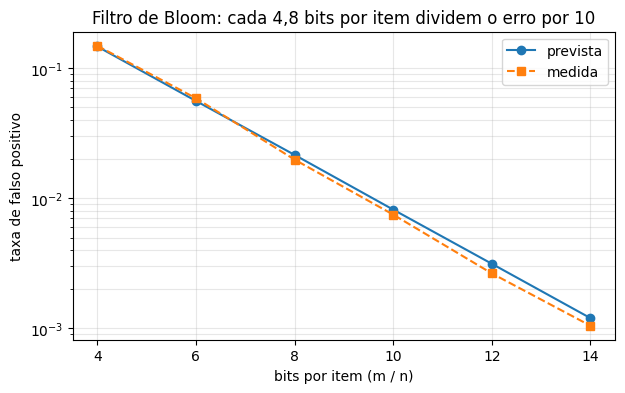

In [7]:
amostra_fora = outros[:20_000]
bits_por_item_testados = [4, 6, 8, 10, 12, 14]
taxas_medidas = []
taxas_previstas = []

for bpi in bits_por_item_testados:
    m_teste = bpi * n
    k_teste = max(1, round(bpi * math.log(2)))
    vetor = bytearray(m_teste)
    for numero in lista_bloqueio:
        resumo = hashlib.blake2b(numero.encode(), digest_size=16).digest()
        ha = int.from_bytes(resumo[:8], "big")
        hb = int.from_bytes(resumo[8:], "big")
        for i in range(k_teste):
            vetor[(ha + i * hb) % m_teste] = 1
    positivos = 0
    for numero in amostra_fora:
        resumo = hashlib.blake2b(numero.encode(), digest_size=16).digest()
        ha = int.from_bytes(resumo[:8], "big")
        hb = int.from_bytes(resumo[8:], "big")
        todos_ligados = True
        for i in range(k_teste):
            if vetor[(ha + i * hb) % m_teste] == 0:
                todos_ligados = False
                break
        if todos_ligados:
            positivos = positivos + 1
    taxas_medidas.append(positivos / len(amostra_fora))
    taxas_previstas.append((1 - math.exp(-k_teste * n / m_teste)) ** k_teste)
    print(f"{bpi:2d} bits/item, k={k_teste:2d}: medida {positivos / len(amostra_fora):.4%}  prevista {taxas_previstas[-1]:.4%}")

plt.figure(figsize=(7, 4))
plt.semilogy(bits_por_item_testados, taxas_previstas, "o-", label="prevista")
plt.semilogy(bits_por_item_testados, taxas_medidas, "s--", label="medida")
plt.xlabel("bits por item (m / n)")
plt.ylabel("taxa de falso positivo")
plt.title("Filtro de Bloom: cada 4,8 bits por item dividem o erro por 10")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

## Filtro de cuco

Tabela de baldes com $b = 4$ posições; cada posição guarda uma impressão digital de $f = 12$ bits. Os dois baldes candidatos são $i_1 = h(x)$ e $i_2 = i_1 \oplus h(\text{fp})$. O número de baldes é uma potência de 2, para que o XOR com o *hash* da impressão digital, reduzido ao mesmo número de bits, continue dentro da tabela e seja simétrico.

In [8]:
b = 4                    # posições por balde
f = 12                   # bits da impressão digital
num_baldes = 2 ** 15     # 32.768 baldes x 4 posições = 131.072 posições
max_deslocamentos = 500
tabela = []
for i in range(num_baldes):
    tabela.append([])

def impressao_e_balde(item):
    h = int.from_bytes(hashlib.blake2b(item.encode(), digest_size=8).digest(), "big")
    fp = h & ((1 << f) - 1)
    if fp == 0:
        fp = 1           # 0 fica reservado; a impressão digital nunca é nula
    i1 = (h >> f) % num_baldes
    return fp, i1

def balde_alternativo(i, fp):
    h_fp = int.from_bytes(hashlib.blake2b(fp.to_bytes(2, "big"), digest_size=8).digest(), "big")
    return (i ^ h_fp) % num_baldes

def cuco_inserir(item):
    fp, i1 = impressao_e_balde(item)
    i2 = balde_alternativo(i1, fp)
    if len(tabela[i1]) < b:
        tabela[i1].append(fp)
        return True
    if len(tabela[i2]) < b:
        tabela[i2].append(fp)
        return True
    # Os dois baldes estão cheios: desaloja uma impressão digital e a leva para o balde alternativo dela.
    i = random.choice([i1, i2])
    for tentativa in range(max_deslocamentos):
        posicao = random.randrange(b)
        desalojada = tabela[i][posicao]
        tabela[i][posicao] = fp
        fp = desalojada
        i = balde_alternativo(i, fp)
        if len(tabela[i]) < b:
            tabela[i].append(fp)
            return True
    return False          # tabela cheia demais

def cuco_consultar(item):
    fp, i1 = impressao_e_balde(item)
    i2 = balde_alternativo(i1, fp)
    return fp in tabela[i1] or fp in tabela[i2]

def cuco_remover(item):
    fp, i1 = impressao_e_balde(item)
    i2 = balde_alternativo(i1, fp)
    if fp in tabela[i1]:
        tabela[i1].remove(fp)
        return True
    if fp in tabela[i2]:
        tabela[i2].remove(fp)
        return True
    return False

In [9]:
falhas = 0
for numero in lista_bloqueio:
    if not cuco_inserir(numero):
        falhas = falhas + 1

ocupadas = 0
for balde in tabela:
    ocupadas = ocupadas + len(balde)
print("falhas de inserção:", falhas)
print("ocupação da tabela:", round(ocupadas / (num_baldes * b) * 100, 1), "%")
print("bits por item:", round(num_baldes * b * f / len(lista_bloqueio), 2))

falsos_negativos = 0
for numero in lista_bloqueio:
    if not cuco_consultar(numero):
        falsos_negativos = falsos_negativos + 1
falsos_positivos = 0
for numero in outros:
    if cuco_consultar(numero):
        falsos_positivos = falsos_positivos + 1
print("falsos negativos:", falsos_negativos)
print("taxa de falso positivo medida:", round(falsos_positivos / len(outros) * 100, 3), "%")
print("limite 2b / 2^f:", round(2 * b / 2 ** f * 100, 3), "%")

falhas de inserção: 0
ocupação da tabela: 76.3 %
bits por item: 15.73


falsos negativos: 0
taxa de falso positivo medida: 0.157 %
limite 2b / 2^f: 0.195 %


A taxa medida fica abaixo do limite $2b/2^f$ porque os baldes não estão todos cheios: o limite supõe as $2b$ posições ocupadas. A tabela deste exemplo tem folga (76% de ocupação, potência de 2 de baldes), e por isso gasta cerca de 15,7 bits por item; com a ocupação perto de 95%, o custo cai para  / 0{,}95 \approx 12{,}6 por item.

### Remoção

O assinante pede para sair da lista. O cadastro garante que ele estava nela; a remoção apaga uma cópia da impressão digital.

In [10]:
saindo = lista_bloqueio[:1000]
presentes = 0
for numero in saindo:
    if cuco_consultar(numero):
        presentes = presentes + 1
print("antes da remoção, presentes:", presentes)
for numero in saindo:
    cuco_remover(numero)
ainda_presentes = 0
for numero in saindo:
    if cuco_consultar(numero):
        ainda_presentes = ainda_presentes + 1
print("depois da remoção, ainda respondem presente:", ainda_presentes)

falsos_negativos = 0
for numero in lista_bloqueio[1000:]:
    if not cuco_consultar(numero):
        falsos_negativos = falsos_negativos + 1
print("falsos negativos entre os que ficaram:", falsos_negativos)

antes da remoção, presentes: 1000
depois da remoção, ainda respondem presente: 2
falsos negativos entre os que ficaram: 0


Os números removidos que ainda respondem "presente" são falsos positivos comuns: outro item da tabela tem a mesma impressão digital num dos dois baldes. Nenhum número que ficou na lista perdeu a sua impressão digital.

## Registro de chamadas com distribuição de Zipf

O registro tem 1.000.000 de chamadas originadas por 50.000 números. A probabilidade de um número originar a próxima chamada é proporcional a $1/r^{1{,}1}$, com $r$ a sua posição no ranking: poucos números (robôs de discagem, centrais de atendimento) concentram boa parte das chamadas.

In [11]:
gerador = np.random.default_rng(42)
originadores = todos[:50_000]
pesos = 1 / np.arange(1, len(originadores) + 1) ** 1.1
pesos = pesos / pesos.sum()
indices = gerador.choice(len(originadores), size=1_000_000, p=pesos)
chamadas = []
for i in indices:
    chamadas.append(originadores[i])

N = len(chamadas)
print(N, "chamadas")
print("primeiras:", chamadas[:3])

1000000 chamadas
primeiras: ['+5511990916826', '+5548930745776', '+5592910206925']


In [12]:
contagem_exata = {}
for origem in chamadas:
    if origem not in contagem_exata:
        contagem_exata[origem] = 0
    contagem_exata[origem] = contagem_exata[origem] + 1
print(len(contagem_exata), "números distintos originaram chamadas")

def pelo_total(par):
    return par[1]

ranking = sorted(contagem_exata.items(), key=pelo_total, reverse=True)
print("os 5 que mais ligaram:")
for numero, total in ranking[:5]:
    print(" ", numero, total)

42444 números distintos originaram chamadas
os 5 que mais ligaram:
  +5512976345403 138835
  +5521972715244 64897
  +5519936088086 41564
  +5548959604008 30153
  +5591966944881 23637


## *Count-min sketch*

$$w = \left\lceil \frac{e}{\varepsilon} \right\rceil, \qquad d = \left\lceil \ln \frac{1}{\delta} \right\rceil$$

Com $\varepsilon = 0{,}0001$ e $\delta = 0{,}01$, o erro fica abaixo de $\varepsilon N = 100$ chamadas com probabilidade de pelo menos 99%.

In [13]:
epsilon = 0.0001
delta = 0.01
w = math.ceil(math.e / epsilon)
d = math.ceil(math.log(1 / delta))
print("w =", w, "colunas")
print("d =", d, "linhas")
print("contadores:", w * d, "->", round(w * d * 4 / 1024), "KB com contadores de 32 bits")

matriz = []
for j in range(d):
    matriz.append([0] * w)

def colunas_cms(item):
    resumo = hashlib.blake2b(item.encode(), digest_size=16).digest()
    ha = int.from_bytes(resumo[:8], "big")
    hb = int.from_bytes(resumo[8:], "big")
    lista = []
    for j in range(d):
        lista.append((ha + j * hb) % w)    # uma coluna por linha, com hash duplo
    return lista

def cms_incrementar(item):
    colunas = colunas_cms(item)
    for j in range(d):
        matriz[j][colunas[j]] = matriz[j][colunas[j]] + 1

def cms_estimar(item):
    colunas = colunas_cms(item)
    menor = matriz[0][colunas[0]]
    for j in range(1, d):
        if matriz[j][colunas[j]] < menor:
            menor = matriz[j][colunas[j]]
    return menor

for origem in chamadas:
    cms_incrementar(origem)

w = 27183 colunas
d = 5 linhas
contadores: 135915 -> 531 KB com contadores de 32 bits


In [14]:
abaixo_do_real = 0
acima_do_limite = 0
for numero, real in contagem_exata.items():
    estimado = cms_estimar(numero)
    if estimado < real:
        abaixo_do_real = abaixo_do_real + 1
    if estimado > real + epsilon * N:
        acima_do_limite = acima_do_limite + 1

print("estimativas abaixo do valor real:", abaixo_do_real)
print("estimativas acima de real + epsilon * N:", acima_do_limite, "de", len(contagem_exata))
print("fração acima do limite:", round(acima_do_limite / len(contagem_exata), 4), "(delta =", delta, ")")

estimativas abaixo do valor real: 0
estimativas acima de real + epsilon * N: 0 de 42444
fração acima do limite: 0.0 (delta = 0.01 )


O erro absoluto é limitado pelo total $N$, e não pela frequência do número: é pequeno em relação aos números frequentes e enorme em relação aos raros.

In [15]:
print(f"{'posição':>8} {'real':>8} {'estimado':>9} {'erro':>6} {'erro relativo':>14}")
for posicao in [1, 10, 100, 1000, 10000, 40000]:
    numero, real = ranking[posicao - 1]
    estimado = cms_estimar(numero)
    print(f"{posicao:>8} {real:>8} {estimado:>9} {estimado - real:>6} {(estimado - real) / real:>14.1%}")

 posição     real  estimado   erro  erro relativo
       1   138835    138835      0           0.0%
      10    11062     11062      0           0.0%
     100      875       880      5           0.6%
    1000       69        71      2           2.9%
   10000        6         6      0           0.0%
   40000        1         2      1         100.0%


## *Top-k*: o algoritmo *Space-Saving*

Mantém exatamente $k$ pares (número, contador). Um número novo, com a lista cheia, substitui o de menor contador e herda esse contador mais 1. Todo número com mais de $N/k$ chamadas está garantidamente na lista.

In [16]:
k_top = 50
monitorados = {}

for origem in chamadas:
    if origem in monitorados:
        monitorados[origem] = monitorados[origem] + 1
    elif len(monitorados) < k_top:
        monitorados[origem] = 1
    else:
        # procura o de menor contador (busca linear, para deixar o passo visível)
        menor_numero = None
        menor_contador = None
        for numero, contador in monitorados.items():
            if menor_contador is None or contador < menor_contador:
                menor_numero = numero
                menor_contador = contador
        del monitorados[menor_numero]
        monitorados[origem] = menor_contador + 1

print("limite N / k =", N // k_top, "chamadas")
print("menor contador na lista:", min(monitorados.values()))

limite N / k = 20000 chamadas
menor contador na lista: 15468


In [17]:
top_estimado = sorted(monitorados.items(), key=pelo_total, reverse=True)
top_real = ranking[:k_top]

conjunto_estimado = set()
for numero, contador in top_estimado[:10]:
    conjunto_estimado.add(numero)
conjunto_real = set()
for numero, total in top_real[:10]:
    conjunto_real.add(numero)
print("dos 10 maiores reais, encontrados entre os 10 maiores estimados:", len(conjunto_estimado & conjunto_real))

print(f"{'número':>16} {'real':>7} {'estimado':>9}")
for numero, contador in top_estimado[:10]:
    print(f"{numero:>16} {contagem_exata[numero]:>7} {contador:>9}")

acima_do_limite = []
for numero, total in ranking:
    if total > N / k_top:
        acima_do_limite.append(numero)
faltando = 0
for numero in acima_do_limite:
    if numero not in monitorados:
        faltando = faltando + 1
print(len(acima_do_limite), "números têm mais de N / k chamadas; fora da lista:", faltando)

dos 10 maiores reais, encontrados entre os 10 maiores estimados: 8
          número    real  estimado
  +5512976345403  138835    138835
  +5521972715244   64897     64897
  +5519936088086   41564     41564
  +5548959604008   30153     30154
  +5591966944881   23637     23637
  +5581910754573   19413     19413
  +5581917493904   16344     16347
  +5541923508888   14116     15472
  +5548958836165    9011     15471
  +5547952662908    7052     15470
5 números têm mais de N / k chamadas; fora da lista: 0


Os sete primeiros da lista têm contador exato ou quase exato: entraram cedo e nunca foram substituídos. Os últimos colocados têm contador próximo de 15.470, valor herdado de quem ocupava a posição antes deles — é a superestimação prevista pelo algoritmo, limitada pelo menor contador, que nunca passa de $N/k$. A garantia vale para os números acima de $N/k$: os cinco estão na lista.